In [70]:
import numpy as np
import seaborn as sd
import matplotlib.pyplot as plt
import pandas as pd
from arch  import arch_model
import yfinance as yf

In [71]:
Infosys=yf.download('INFY.NS',start='2016-10-28',end='2026-10-29')['Close']
Infosys=Infosys.rename(columns={'INFY.NS':'Price'})

[*********************100%***********************]  1 of 1 completed


In [72]:
Infosys['Return']=Infosys['Price'].pct_change().fillna(0)*100
Infosys

C:\Users\arpit\AppData\Local\Temp\ipykernel_5696\3475728921.py:1: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  Infosys['Return']=Infosys['Price'].pct_change().fillna(0)*100


Ticker,Price,Return
Date,,
2016-10-28,381.030243,0.000000
2016-11-01,377.955292,-0.807010
2016-11-02,374.746460,-0.848998
2016-11-03,369.322388,-1.447398
2016-11-04,370.907654,0.429236
...,...,...
2026-10-22,1153.349976,-1.254283
2026-10-23,1153.800049,0.039023
2026-10-26,1166.000000,1.057371


In [73]:
EGARCH_Model=arch_model(Infosys['Return'],vol='EGARCH',p=1,q=1,o=1)
EGARCH_Result=EGARCH_Model.fit(disp='off')
print('\n                   --EGARCH_MODEL SUMMARY--')
EGARCH_Result.summary()


                   --EGARCH_MODEL SUMMARY--


<class 'statsmodels.iolib.summary.Summary'>
"""
                     Constant Mean - EGARCH Model Results                     
==============================================================================
Dep. Variable:                 Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                     EGARCH   Log-Likelihood:               -4696.87
Distribution:                  Normal   AIC:                           9403.73
Method:            Maximum Likelihood   BIC:                           9432.80
                                        No. Observations:                 2471
Date:                Thu, Oct 29 2026   Df Residuals:                     2470
Time:                        00:12:57   Df Model:                            1
                                Mean Model                                
==========================================================================
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.0831  3.089e-02      2.691  7.126e-03 [2.258e-02,  0.144]
                              Volatility Model                             
===========================================================================
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
omega          0.0552  2.367e-02      2.331  1.973e-02  [8.793e-03,  0.102]
alpha[1]       0.1374  4.623e-02      2.973  2.947e-03  [4.684e-02,  0.228]
gamma[1]      -0.0583  2.215e-02     -2.631  8.513e-03 [ -0.102,-1.486e-02]
beta[1]        0.9529  2.167e-02     43.980      0.000    [  0.910,  0.995]
===========================================================================

Covariance estimator: robust
"""

In [74]:
Realised_Volatility=Infosys['Return'].abs()
EGARCH_Volatility=EGARCH_Result.conditional_volatility

In [75]:
Volatility=pd.DataFrame({'Real Volatility':Realised_Volatility,
                         'EGARCH Volatility':EGARCH_Volatility})

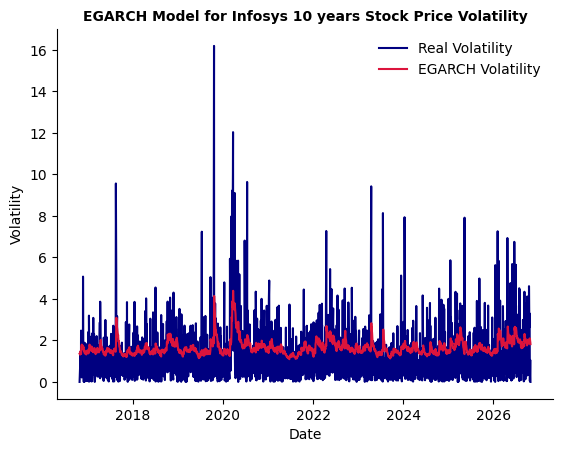

In [76]:
sd.lineplot(data=Volatility,dashes=False,palette={'Real Volatility':'navy','EGARCH Volatility':'crimson'})
plt.title('EGARCH Model for Infosys 10 years Stock Price Volatility',fontsize=10,fontweight='bold',)
plt.ylabel('Volatility')
ax=plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.legend(frameon=False);